import

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

dataset
UIC Injections

                              time   latitude   longitude   mag
0 2010-01-01 00:10:43.792000+00:00  61.032200 -151.658700  1.60
1 2010-01-01 00:16:49.190000+00:00  48.203167 -121.676833  2.20
2 2010-01-01 00:16:54.480000+00:00  36.032000 -117.782167  1.10
3 2010-01-01 00:29:29.585000+00:00  60.147000 -141.055000  1.40
4 2010-01-01 00:30:16.720000+00:00  33.474667 -116.426833  0.75
(2119693, 4)
['time', 'latitude', 'longitude', 'mag']
            injection_volume  active_wells
date                                      
2011-01-01      1.635255e+08         10386
2011-02-01      1.448641e+08         10386
2011-03-01      1.687305e+08         10386
2011-04-01      1.622064e+08         10386
2011-05-01      1.675129e+08         10386
            earthquake_frequency  max_magnitude  mean_magnitude
date                                                           
2010-01-01                     9            3.8        3.088889
2010-02-01                    11            4.1        2.890909
2010-

C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\4185224753.py:95: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period('M')


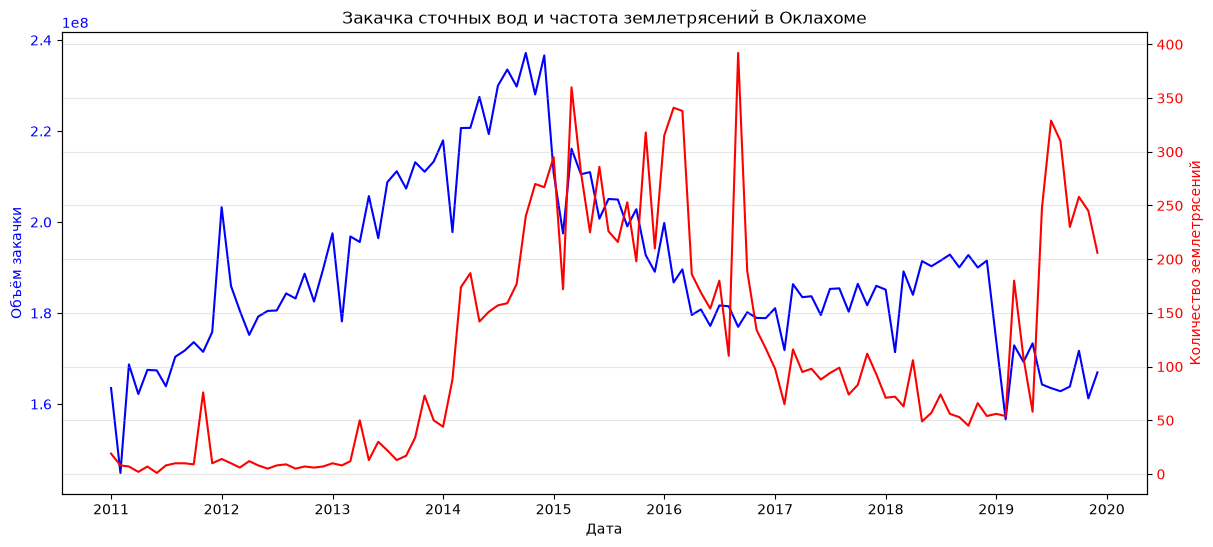

In [31]:
# 1. Загрузка датасетов

file_path = 'data/uic_injection_volumes_2011_2019.csv'
df = pd.read_csv(file_path)

earthquakes = pd.read_csv(
    'data/earthquakes_2010_2026.csv',
    usecols=['time', 'latitude', 'longitude', 'mag'],
    parse_dates=['time']
)

print(earthquakes.head())
print(earthquakes.shape)
print(earthquakes.columns.tolist())

# 2. Подготовка данных о закачке

months = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

volume_columns = [f'{month} Vol' for month in months]

# Оставляем только корректные координаты Оклахомы
injection_source = df.dropna(
    subset=['API', 'Year', 'LAT', 'LON']
).copy()

injection_source = injection_source[
    injection_source['LAT'].between(33, 37) &
    injection_source['LON'].between(-103, -94)
]

volume_long = injection_source.melt(
    id_vars=['API', 'Year', 'County', 'LAT', 'LON'],
    value_vars=volume_columns,
    var_name='month',
    value_name='injection_volume'
)

volume_long['month'] = volume_long['month'].str.replace(
    ' Vol',
    '',
    regex=False
)

month_numbers = {
    month: number
    for number, month in enumerate(months, start=1)
}

volume_long['month_number'] = (
    volume_long['month'].map(month_numbers)
)

volume_long['date'] = pd.to_datetime(
    dict(
        year=volume_long['Year'],
        month=volume_long['month_number'],
        day=1
    )
)

monthly_injection = (
    volume_long
    .groupby('date')
    .agg(
        injection_volume=('injection_volume', 'sum'),
        active_wells=('API', 'nunique')
    )
    .sort_index()
)

print(monthly_injection.head())

# injection_volume — месячный объём закачки;
# active_wells — количество скважин;
# date — месяц.

# 3. Подготовка землетрясений Оклахомы

earthquakes_ok = earthquakes.dropna(
    subset=['time', 'latitude', 'longitude', 'mag']
).copy()

# Приближённые границы Оклахомы
earthquakes_ok = earthquakes_ok[
    earthquakes_ok['latitude'].between(33, 37) &
    earthquakes_ok['longitude'].between(-103, -94)
]

earthquakes_ok['date'] = (
    earthquakes_ok['time']
    .dt.to_period('M')
    .dt.to_timestamp()
)

monthly_earthquakes = (
    earthquakes_ok
    .groupby('date')
    .agg(
        earthquake_frequency=('mag', 'size'),
        max_magnitude=('mag', 'max'),
        mean_magnitude=('mag', 'mean')
    )
    .sort_index()
)

print(monthly_earthquakes.head())
print(monthly_earthquakes.tail())

# earthquake_frequency — количество землетрясений за месяц;
# max_magnitude — самое сильное землетрясение;
# mean_magnitude — средняя магнитуда.

# 4. Объединение двух датасетов

analysis_data = monthly_injection.join(
    monthly_earthquakes,
    how='left'
)

analysis_data['earthquake_frequency'] = (
    analysis_data['earthquake_frequency']
    .fillna(0)
)

analysis_data['max_magnitude'] = (
    analysis_data['max_magnitude']
    .fillna(0)
)

analysis_data['mean_magnitude'] = (
    analysis_data['mean_magnitude']
    .fillna(0)
)

print(analysis_data.head())
print(analysis_data.columns)

# 5. График закачки и землетрясений

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    analysis_data.index,
    analysis_data['injection_volume'],
    color='blue',
    label='Объём закачки'
)

ax1.set_xlabel('Дата')
ax1.set_ylabel('Объём закачки', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()

ax2.plot(
    analysis_data.index,
    analysis_data['earthquake_frequency'],
    color='red',
    label='Количество землетрясений'
)

ax2.set_ylabel(
    'Количество землетрясений',
    color='red'
)
ax2.tick_params(axis='y', labelcolor='red')

plt.title(
    'Закачка сточных вод и частота землетрясений в Оклахоме'
)
plt.grid(alpha=0.3)
plt.show()

Preskúmajte a analyzujte pridelené dáta tak, aby ste dokázali opísať ich obsah, charakteristiky, priestorové a časové vlastnosti, identifikovať zaujímavé vzory a závislosti a na základe vykonanej analýzy vysvetliť, čo sa v dátach deje a aké závery z nich možno vyvodiť.
1. <br>
2. <br>
3. <br>
4. <br>
5. <br>
6. <br>
7. <br>
8. <br>
9. <br>
10. <br>

In [18]:
# 1. Подготовка временного ряда

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

volume_columns = [f'{month} Vol' for month in months]

# Переводим месяцы из отдельных столбцов в строки
volume_long = df.melt(
    id_vars=['API', 'Year'],
    value_vars=volume_columns,
    var_name='month',
    value_name='volume'
)

# Название месяца: "Jan Vol" -> "Jan"
volume_long['month'] = volume_long['month'].str.replace(
    ' Vol', '', regex=False
)

# Номер месяца
month_numbers = {month: number for number, month in enumerate(months, start=1)}
volume_long['month_number'] = volume_long['month'].map(month_numbers)

# Создаём дату: первое число каждого месяца
volume_long['date'] = pd.to_datetime(
    dict(
        year=volume_long['Year'],
        month=volume_long['month_number'],
        day=1
    )
)

# Агрегируем данные по всем скважинам
monthly = (
    volume_long
    .groupby('date')
    .agg(
        total_volume=('volume', 'sum'),
        mean_volume=('volume', 'mean'),
        number_of_records=('volume', 'count')
    )
    .sort_index()
)

print(monthly.head())
print(monthly.tail())

            total_volume   mean_volume  number_of_records
date                                                     
2011-01-01  1.635255e+08  15735.706126              10392
2011-02-01  1.448641e+08  13939.962077              10392
2011-03-01  1.687305e+08  16236.574843              10392
2011-04-01  1.622064e+08  15608.772211              10392
2011-05-01  1.675129e+08  16119.409684              10392
            total_volume   mean_volume  number_of_records
date                                                     
2019-08-01   163300974.0  14376.351263              11359
2019-09-01   164399716.0  14473.080025              11359
2019-10-01   172283879.0  15167.169557              11359
2019-11-01   161778826.0  14242.347566              11359
2019-12-01   167208721.0  14720.373360              11359


Используемый период: 2011–2019


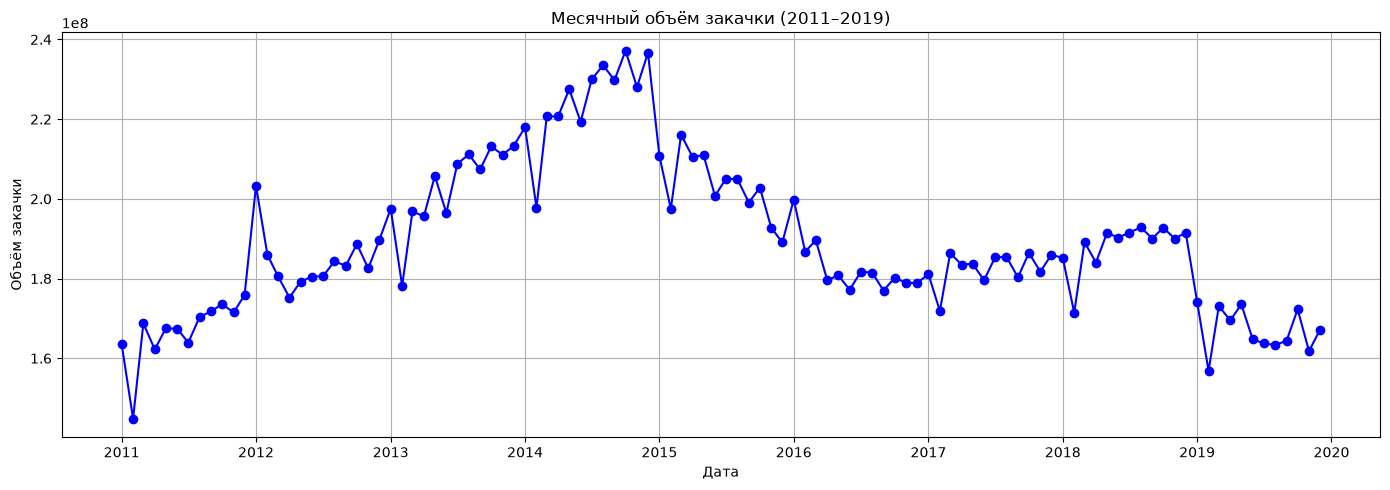

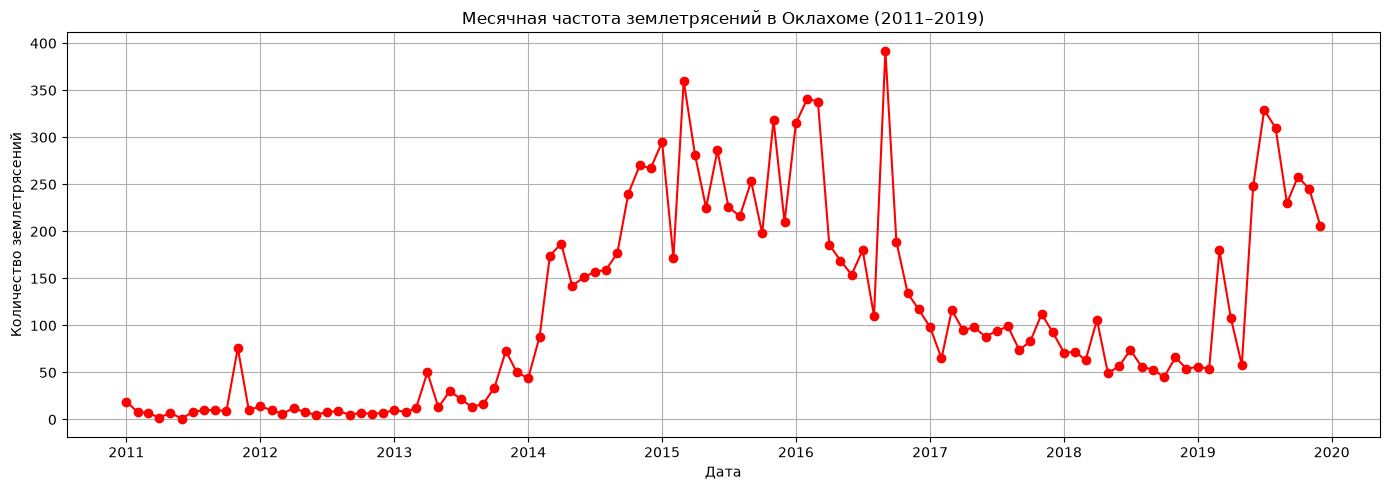

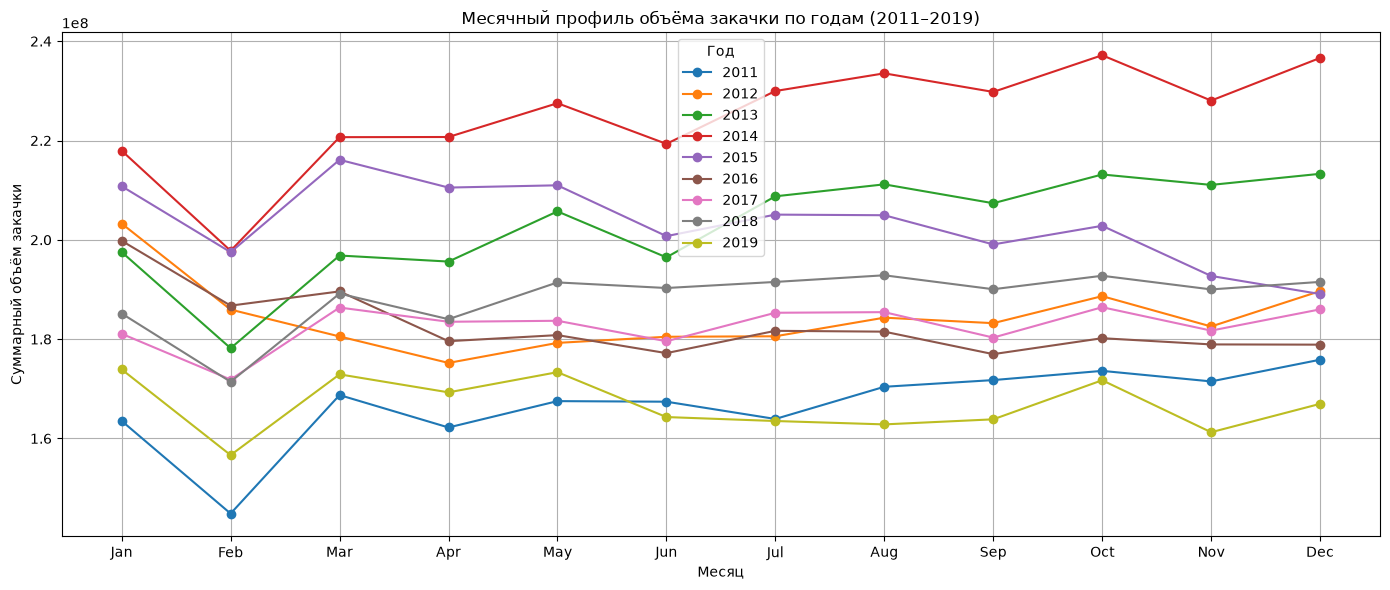

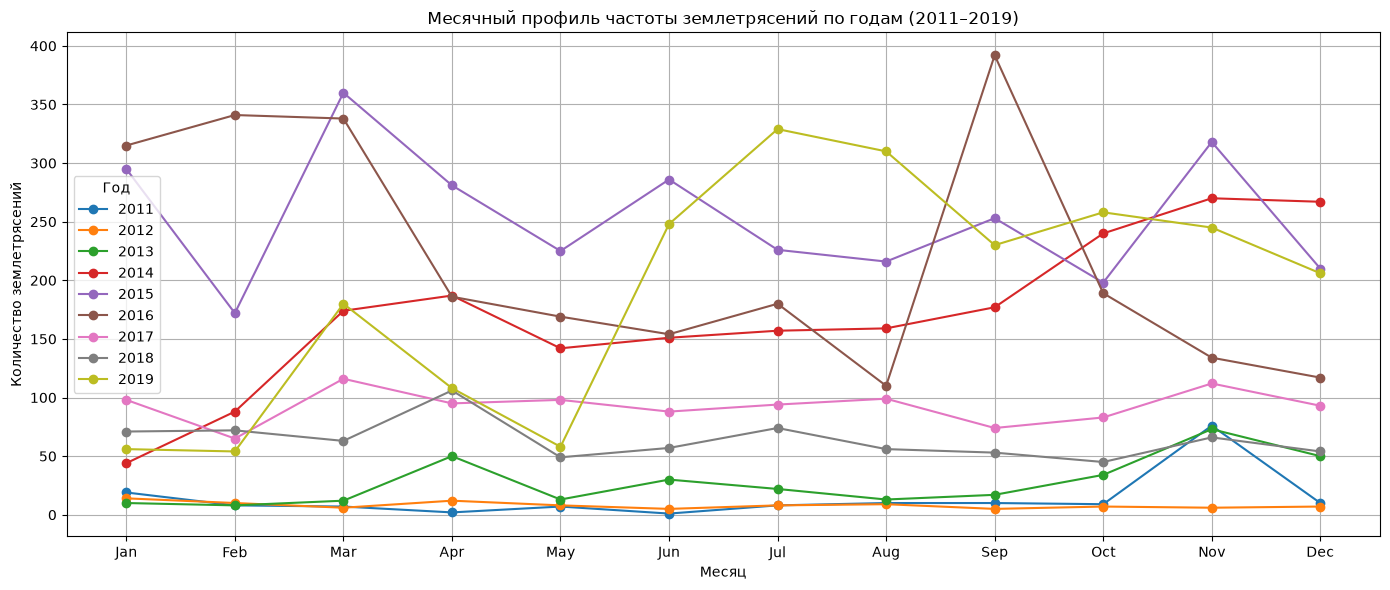

In [35]:
# 2. Тренд и сезонность

# Определяем общий период данных о закачке
start_date = monthly.index.min()
end_date = monthly.index.max()

start_year = start_date.year
end_year = end_date.year

print(
    f'Используемый период: '
    f'{start_year}–{end_year}'
)


# -------------------------------
# 1. Фильтрация землетрясений
# -------------------------------

earthquakes_common = earthquakes_ok[
    (earthquakes_ok['date'] >= start_date) &
    (earthquakes_ok['date'] <= end_date)
].copy()

earthquakes_common['Year'] = (
    earthquakes_common['date'].dt.year
)

earthquakes_common['month'] = (
    earthquakes_common['date'].dt.month_name().str[:3]
)


# -------------------------------
# 2. Тренд объёма закачки
# -------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    monthly.index,
    monthly['total_volume'],
    marker='o',
    color='blue'
)

plt.title(
    f'Месячный объём закачки ({start_year}–{end_year})'
)
plt.xlabel('Дата')
plt.ylabel('Объём закачки')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 3. Тренд частоты землетрясений
# -------------------------------

monthly_earthquakes_common = (
    earthquakes_common
    .groupby('date')
    .size()
    .reindex(monthly.index, fill_value=0)
)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_earthquakes_common.index,
    monthly_earthquakes_common.values,
    marker='o',
    color='red'
)

plt.title(
    f'Месячная частота землетрясений '
    f'в Оклахоме ({start_year}–{end_year})'
)
plt.xlabel('Дата')
plt.ylabel('Количество землетрясений')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 4. Сезонность закачки
# -------------------------------

volume_long_common = volume_long[
    volume_long['Year'].between(start_year, end_year)
].copy()

seasonal_injection = (
    volume_long_common
    .groupby(['Year', 'month'])['injection_volume']
    .sum()
    .unstack()
    .reindex(columns=months)
)

plt.figure(figsize=(14, 6))

for year in seasonal_injection.index:
    plt.plot(
        months,
        seasonal_injection.loc[year],
        marker='o',
        label=str(year)
    )

plt.title(
    f'Месячный профиль объёма закачки '
    f'по годам ({start_year}–{end_year})'
)
plt.xlabel('Месяц')
plt.ylabel('Суммарный объём закачки')
plt.legend(title='Год')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 5. Сезонность землетрясений
# -------------------------------

seasonal_earthquakes = (
    earthquakes_common
    .groupby(['Year', 'month'])
    .size()
    .unstack()
    .reindex(columns=months)
    .fillna(0)
)

plt.figure(figsize=(14, 6))

for year in seasonal_earthquakes.index:
    plt.plot(
        months,
        seasonal_earthquakes.loc[year],
        marker='o',
        label=str(year)
    )

plt.title(
    f'Месячный профиль частоты землетрясений '
    f'по годам ({start_year}–{end_year})'
)
plt.xlabel('Месяц')
plt.ylabel('Количество землетрясений')
plt.legend(title='Год')
plt.grid(True)
plt.tight_layout()
plt.show()

Ряд объёма закачки:
date
2011-01-01    1.635255e+08
2011-02-01    1.448641e+08
2011-03-01    1.687305e+08
2011-04-01    1.622064e+08
2011-05-01    1.675129e+08
Freq: MS, Name: total_volume, dtype: float64
Период: 2011-01-01 — 2019-12-01
Ряд частоты землетрясений:
date
2011-01-01    19.0
2011-02-01     8.0
2011-03-01     7.0
2011-04-01     2.0
2011-05-01     7.0
Freq: MS, dtype: float64


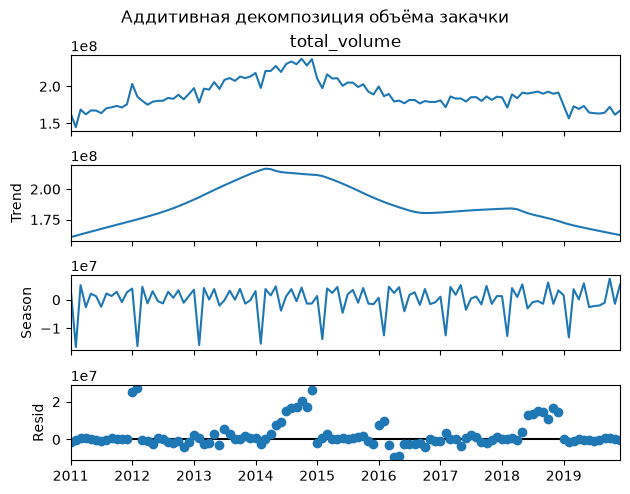

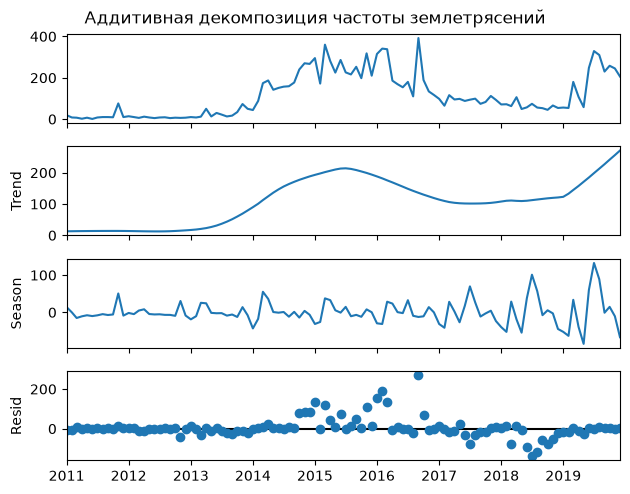

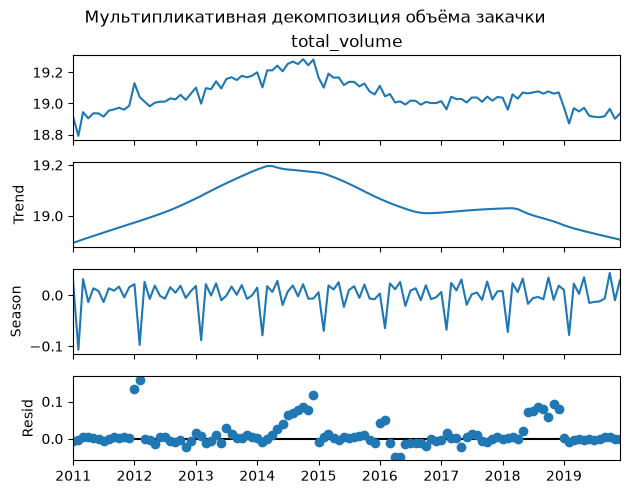

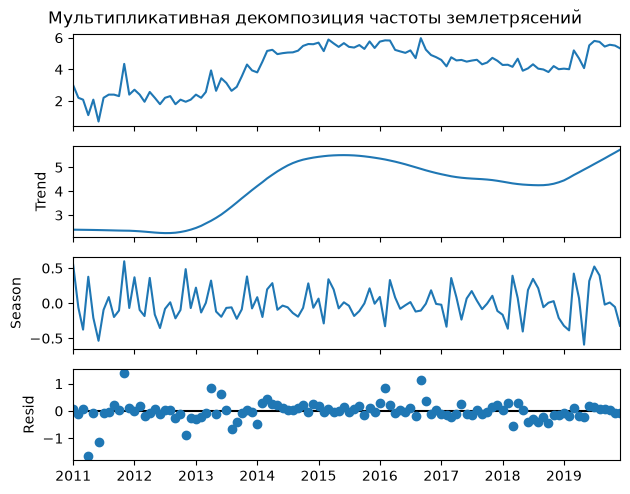

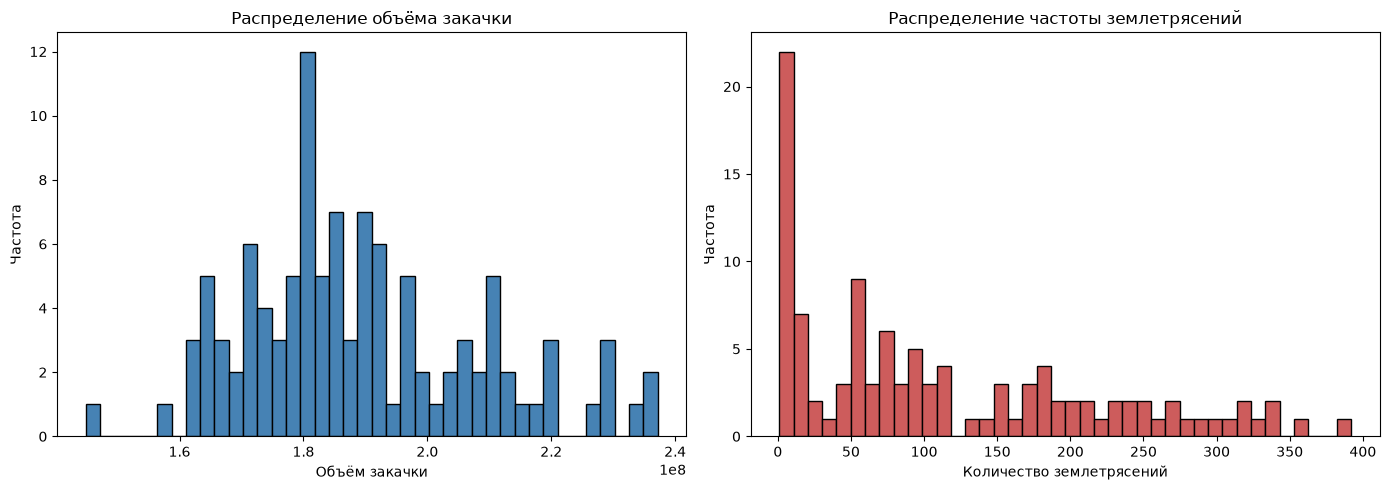

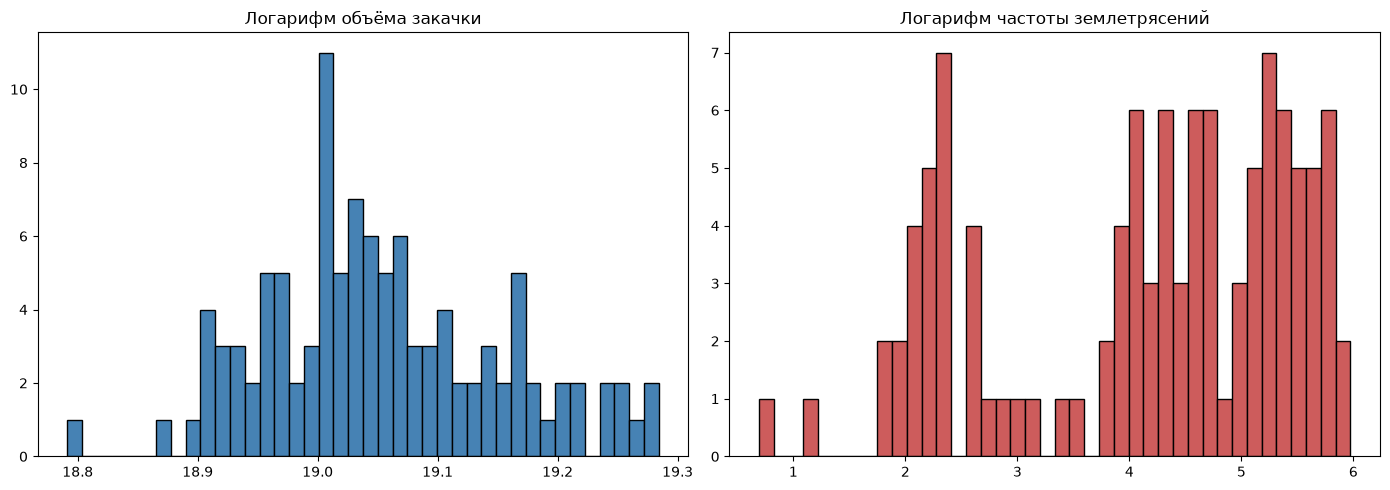

In [38]:
# 3. Аддитивная и мультипликативная сезонность

# -------------------------------
# 1. Временной ряд закачки
# -------------------------------

injection_series = (
    monthly['total_volume']
    .sort_index()
    .asfreq('MS')
    .interpolate()
)

print('Ряд объёма закачки:')
print(injection_series.head())
print(
    f'Период: {injection_series.index.min().date()} — '
    f'{injection_series.index.max().date()}'
)


# -------------------------------
# 2. Временной ряд землетрясений
# -------------------------------

earthquake_series = (
    monthly_earthquakes_common
    .reindex(injection_series.index, fill_value=0)
    .astype(float)
)

print('Ряд частоты землетрясений:')
print(earthquake_series.head())


# -------------------------------
# 3. Аддитивная декомпозиция закачки
# -------------------------------

injection_additive = STL(
    injection_series,
    period=12,
    robust=True
).fit()

injection_additive.plot()
plt.suptitle(
    'Аддитивная декомпозиция объёма закачки',
    y=1.02
)
plt.show()


# -------------------------------
# 4. Аддитивная декомпозиция землетрясений
# -------------------------------

earthquake_additive = STL(
    earthquake_series,
    period=12,
    robust=True
).fit()

earthquake_additive.plot()
plt.suptitle(
    'Аддитивная декомпозиция частоты землетрясений',
    y=1.02
)
plt.show()


# -------------------------------
# 5. Мультипликативная декомпозиция закачки
# -------------------------------

log_injection = np.log1p(injection_series)

injection_multiplicative = STL(
    log_injection,
    period=12,
    robust=True
).fit()

injection_multiplicative.plot()
plt.suptitle(
    'Мультипликативная декомпозиция объёма закачки',
    y=1.02
)
plt.show()


# -------------------------------
# 6. Мультипликативная декомпозиция землетрясений
# -------------------------------

log_earthquakes = np.log1p(earthquake_series)

earthquake_multiplicative = STL(
    log_earthquakes,
    period=12,
    robust=True
).fit()

earthquake_multiplicative.plot()
plt.suptitle(
    'Мультипликативная декомпозиция частоты землетрясений',
    y=1.02
)
plt.show()


# -------------------------------
# 7. Сравнение исходных распределений
# -------------------------------

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(
    injection_series,
    bins=40,
    color='steelblue',
    edgecolor='black'
)
plt.title('Распределение объёма закачки')
plt.xlabel('Объём закачки')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
plt.hist(
    earthquake_series,
    bins=40,
    color='indianred',
    edgecolor='black'
)
plt.title('Распределение частоты землетрясений')
plt.xlabel('Количество землетрясений')
plt.ylabel('Частота')

plt.tight_layout()
plt.show()


# -------------------------------
# 8. Распределения после логарифмирования
# -------------------------------

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(
    log_injection,
    bins=40,
    color='steelblue',
    edgecolor='black'
)
plt.title('Логарифм объёма закачки')

plt.subplot(1, 2, 2)
plt.hist(
    log_earthquakes,
    bins=40,
    color='indianred',
    edgecolor='black'
)
plt.title('Логарифм частоты землетрясений')

plt.tight_layout()
plt.show()

Годовая статистика объёма закачки:
              mean           std  median    min        max
Year                                                      
2011  16047.945153  49650.317428  3516.5 -434.0  1781945.0
2012  16920.819259  56901.880487  3306.0    0.0  2528313.0
2013  18416.350825  57644.110659  3660.0    0.0  2042348.0
2014  19936.457877  63348.712609  3800.0    0.0  2089704.0
2015  18617.997619  58382.249532  3548.0    0.0  1986359.0
2016  16458.507528  45315.948932  2848.5    0.0  1370947.0
2017  16192.417406  43099.661186  2615.0    0.0  1057307.0
2018  16821.262273  65623.200948  2504.0 -500.0  4013325.0
2019  14703.333629  42346.604193  1769.0    0.0  3660088.0

Годовая статистика землетрясений:
      frequency  mean_magnitude  min_magnitude  max_magnitude
Year                                                         
2011        167        2.886228           1.40            5.7
2012         97        2.816495           1.80            4.1
2013        332        2.757229  

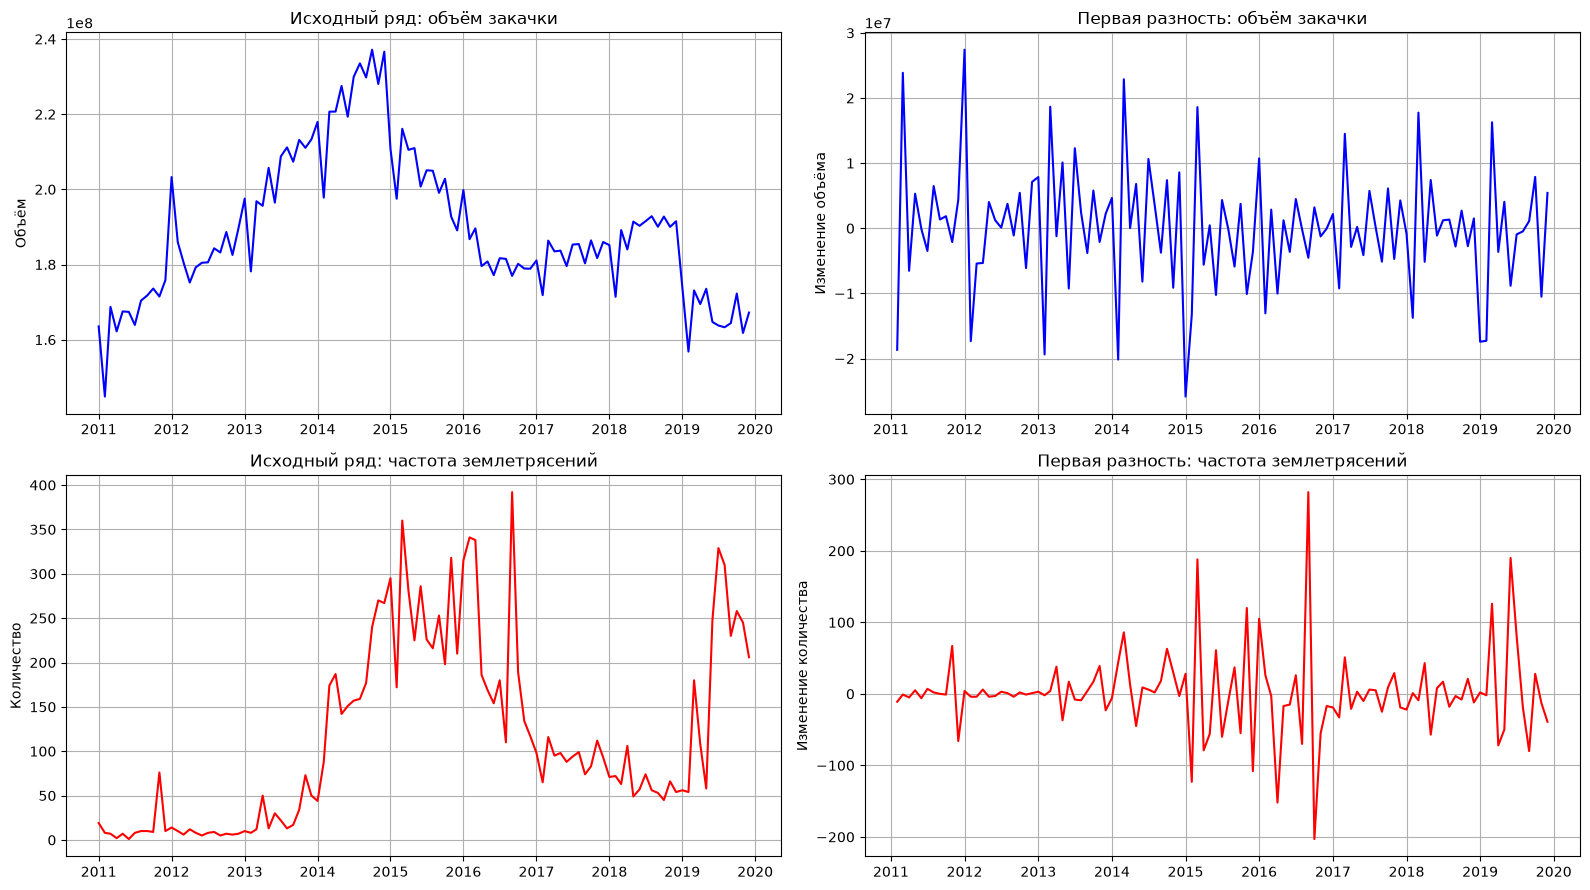

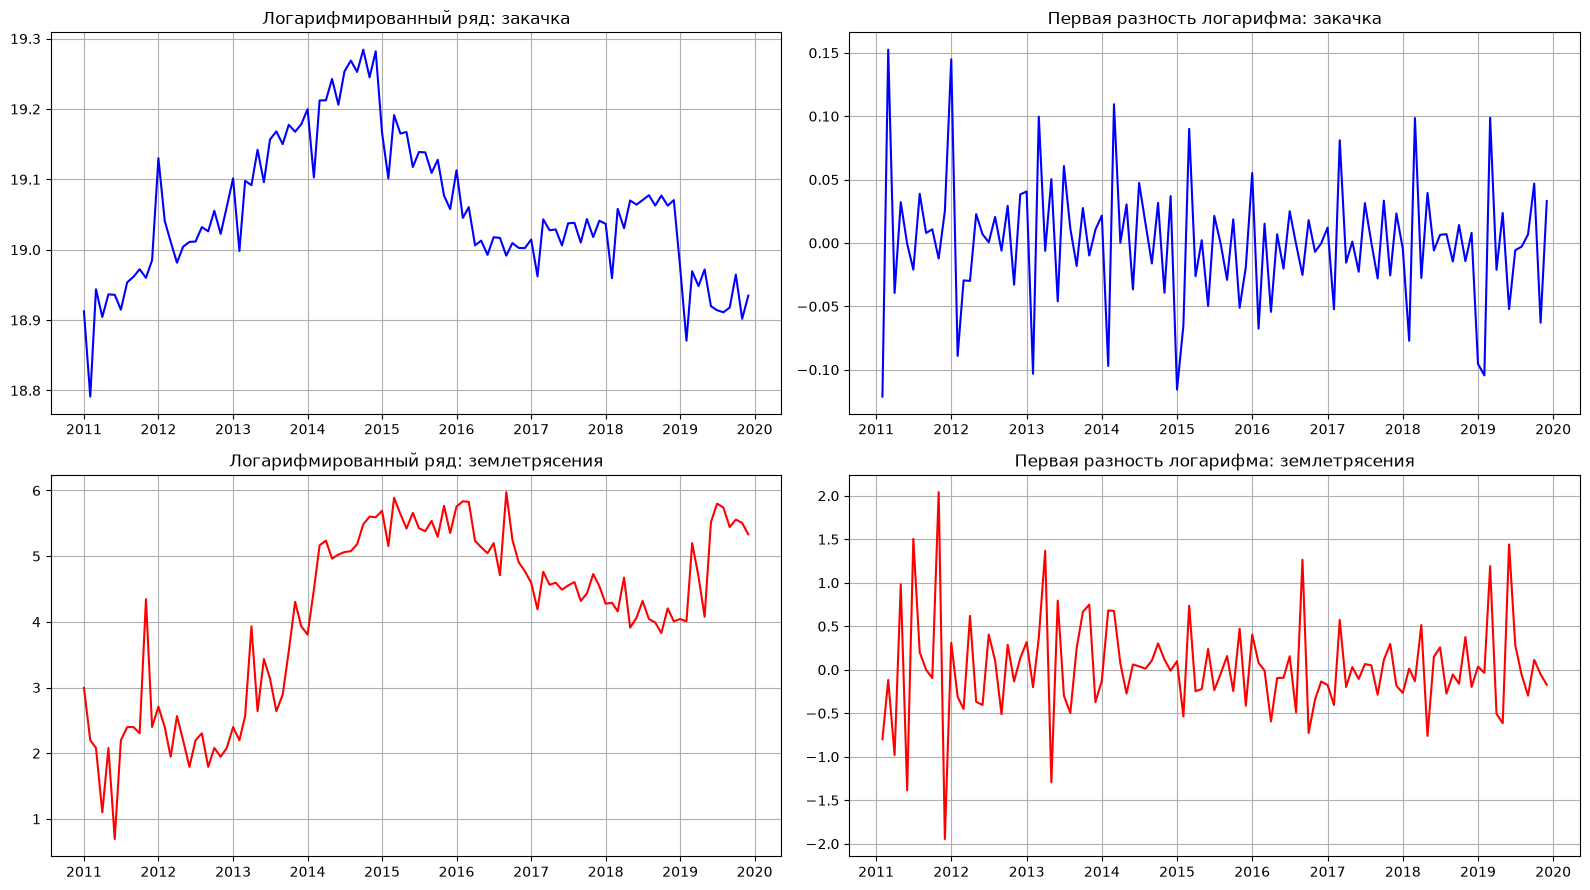

In [39]:
# 4. Стационарность

# -------------------------------
# 1. Годовая статистика закачки
# -------------------------------

injection_year_statistics = (
    volume_long
    .groupby('Year')['injection_volume']
    .agg(
        mean='mean',
        std='std',
        median='median',
        min='min',
        max='max'
    )
)

print('Годовая статистика объёма закачки:')
print(injection_year_statistics)


# -------------------------------
# 2. Годовая статистика землетрясений
# -------------------------------

earthquake_year_statistics = (
    earthquakes_common
    .groupby('Year')['mag']
    .agg(
        frequency='count',
        mean_magnitude='mean',
        min_magnitude='min',
        max_magnitude='max'
    )
)

print('\nГодовая статистика землетрясений:')
print(earthquake_year_statistics)


# -------------------------------
# 3. Первые разности
# -------------------------------

injection_diff = (
    injection_series
    .diff()
    .dropna()
)

earthquake_diff = (
    earthquake_series
    .diff()
    .dropna()
)


# -------------------------------
# 4. Исходные ряды и первые разности
# -------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9),
    sharex=False
)

axes[0, 0].plot(
    injection_series.index,
    injection_series,
    color='blue'
)
axes[0, 0].set_title(
    'Исходный ряд: объём закачки'
)
axes[0, 0].set_ylabel('Объём')
axes[0, 0].grid(True)

axes[0, 1].plot(
    injection_diff.index,
    injection_diff,
    color='blue'
)
axes[0, 1].set_title(
    'Первая разность: объём закачки'
)
axes[0, 1].set_ylabel('Изменение объёма')
axes[0, 1].grid(True)

axes[1, 0].plot(
    earthquake_series.index,
    earthquake_series,
    color='red'
)
axes[1, 0].set_title(
    'Исходный ряд: частота землетрясений'
)
axes[1, 0].set_ylabel('Количество')
axes[1, 0].grid(True)

axes[1, 1].plot(
    earthquake_diff.index,
    earthquake_diff,
    color='red'
)
axes[1, 1].set_title(
    'Первая разность: частота землетрясений'
)
axes[1, 1].set_ylabel('Изменение количества')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


# -------------------------------
# 5. Логарифмированные ряды
# -------------------------------

log_injection_diff = (
    log_injection
    .diff()
    .dropna()
)

log_earthquake_diff = (
    log_earthquakes
    .diff()
    .dropna()
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9),
    sharex=False
)

axes[0, 0].plot(
    log_injection.index,
    log_injection,
    color='blue'
)
axes[0, 0].set_title(
    'Логарифмированный ряд: закачка'
)
axes[0, 0].grid(True)

axes[0, 1].plot(
    log_injection_diff.index,
    log_injection_diff,
    color='blue'
)
axes[0, 1].set_title(
    'Первая разность логарифма: закачка'
)
axes[0, 1].grid(True)

axes[1, 0].plot(
    log_earthquakes.index,
    log_earthquakes,
    color='red'
)
axes[1, 0].set_title(
    'Логарифмированный ряд: землетрясения'
)
axes[1, 0].grid(True)

axes[1, 1].plot(
    log_earthquake_diff.index,
    log_earthquake_diff,
    color='red'
)
axes[1, 1].set_title(
    'Первая разность логарифма: землетрясения'
)
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

In [40]:
# 5. Тесты стационарности ADF и KPSS

def stationarity_tests(data, name):
    data = data.dropna()

    adf_result = adfuller(
        data,
        autolag='AIC'
    )

    kpss_result = kpss(
        data,
        regression='c',
        nlags='auto'
    )

    print(f'\n{name}')
    print('-' * 60)

    print(
        f'ADF statistic: '
        f'{adf_result[0]:.4f}'
    )
    print(
        f'ADF p-value: '
        f'{adf_result[1]:.4f}'
    )

    print(
        f'KPSS statistic: '
        f'{kpss_result[0]:.4f}'
    )
    print(
        f'KPSS p-value: '
        f'{kpss_result[1]:.4f}'
    )

    print('\nВывод:')

    if adf_result[1] < 0.05:
        print(
            'ADF: есть основания считать ряд стационарным'
        )
    else:
        print(
            'ADF: нет оснований считать ряд стационарным'
        )

    if kpss_result[1] > 0.05:
        print(
            'KPSS: нет оснований отвергать стационарность'
        )
    else:
        print(
            'KPSS: ряд, вероятно, нестационарен'
        )


# --------------------------------
# 1. Исходные ряды
# --------------------------------

stationarity_tests(
    injection_series,
    'Исходный ряд: объём закачки'
)

stationarity_tests(
    earthquake_series,
    'Исходный ряд: частота землетрясений'
)


# --------------------------------
# 2. Первые разности
# --------------------------------

stationarity_tests(
    injection_diff,
    'Первая разность: объём закачки'
)

stationarity_tests(
    earthquake_diff,
    'Первая разность: частота землетрясений'
)


# --------------------------------
# 3. Логарифмированные ряды
# --------------------------------

stationarity_tests(
    log_injection,
    'Логарифмированный ряд: объём закачки'
)

stationarity_tests(
    log_earthquakes,
    'Логарифмированный ряд: частота землетрясений'
)


# --------------------------------
# 4. Первые разности логарифмов
# --------------------------------

stationarity_tests(
    log_injection_diff,
    'Первая разность логарифма: объём закачки'
)

stationarity_tests(
    log_earthquake_diff,
    'Первая разность логарифма: частота землетрясений'
)


Исходный ряд: объём закачки
------------------------------------------------------------
ADF statistic: -1.1396
ADF p-value: 0.6990
KPSS statistic: 0.3992
KPSS p-value: 0.0775

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: нет оснований отвергать стационарность

Исходный ряд: частота землетрясений
------------------------------------------------------------
ADF statistic: -1.6727
ADF p-value: 0.4452
KPSS statistic: 0.6153
KPSS p-value: 0.0212

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: ряд, вероятно, нестационарен

Первая разность: объём закачки
------------------------------------------------------------
ADF statistic: -2.6530
ADF p-value: 0.0825
KPSS statistic: 0.2772
KPSS p-value: 0.1000

Вывод:
ADF: нет оснований считать ряд стационарным
KPSS: нет оснований отвергать стационарность

Первая разность: частота землетрясений
------------------------------------------------------------
ADF statistic: -2.9664
ADF p-value: 0.0382
KPSS statistic: 0.0840
KPSS p-val

C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\1000599866.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\1000599866.py:11: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(
C:\Users\Денис\AppData\Local\Temp\ipykernel_24744\1000599866.py:6

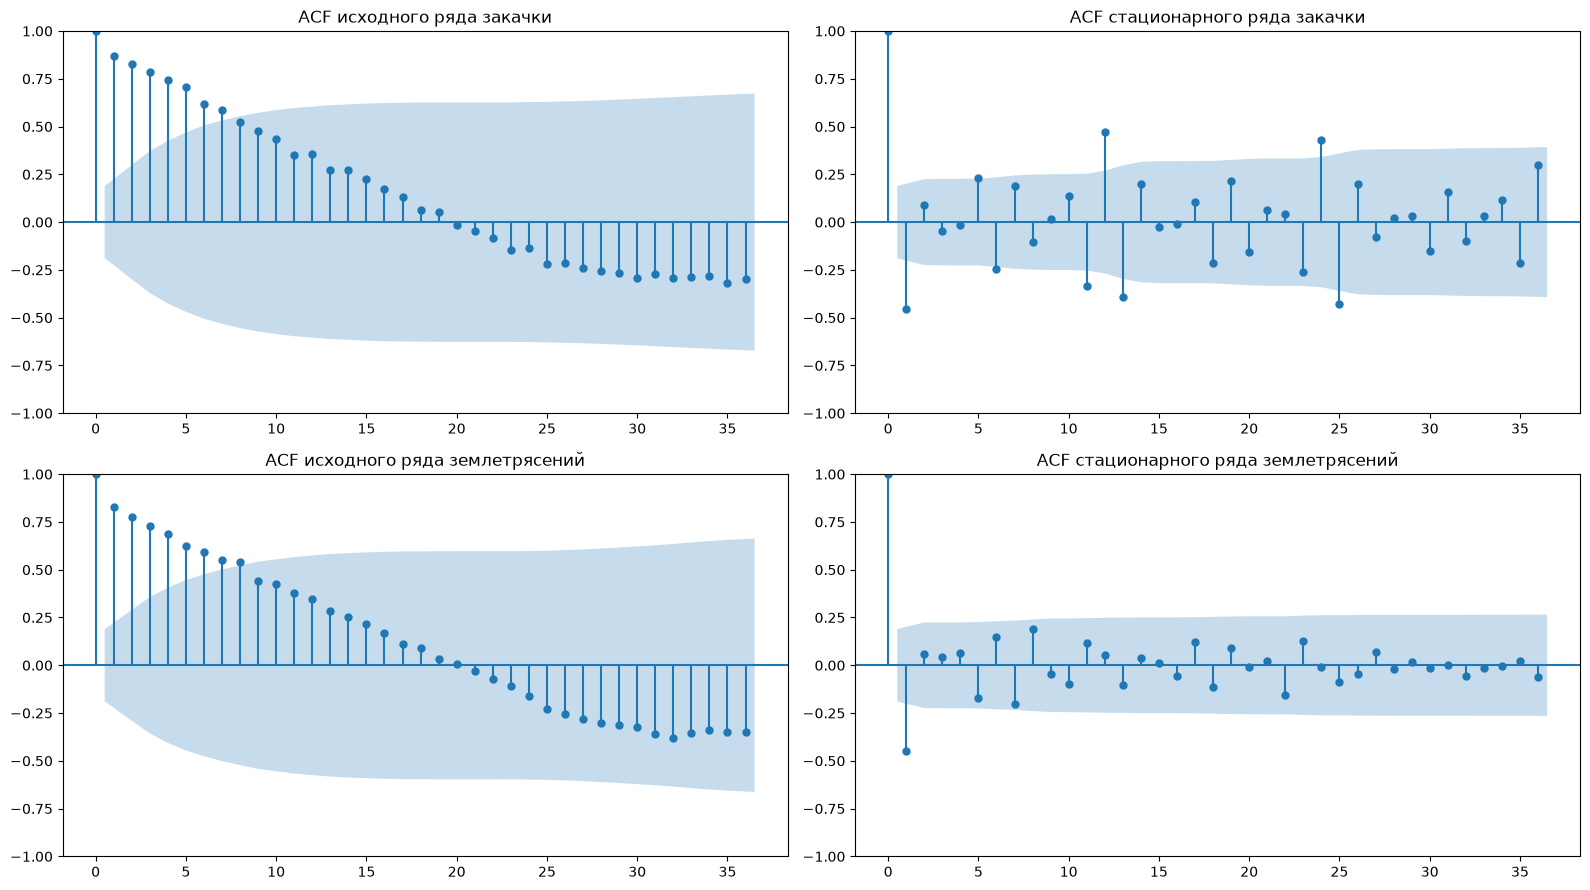

Автокорреляция объёма закачки:
Лаг 1: 0.8809
Лаг 2: 0.8684
Лаг 3: 0.8322
Лаг 6: 0.6875
Лаг 12: 0.4111
Лаг 24: -0.2041
Лаг 36: -0.4345

Автокорреляция частоты землетрясений:
Лаг 1: 0.8340
Лаг 2: 0.7929
Лаг 3: 0.7583
Лаг 6: 0.6616
Лаг 12: 0.4124
Лаг 24: -0.2004
Лаг 36: -0.5324


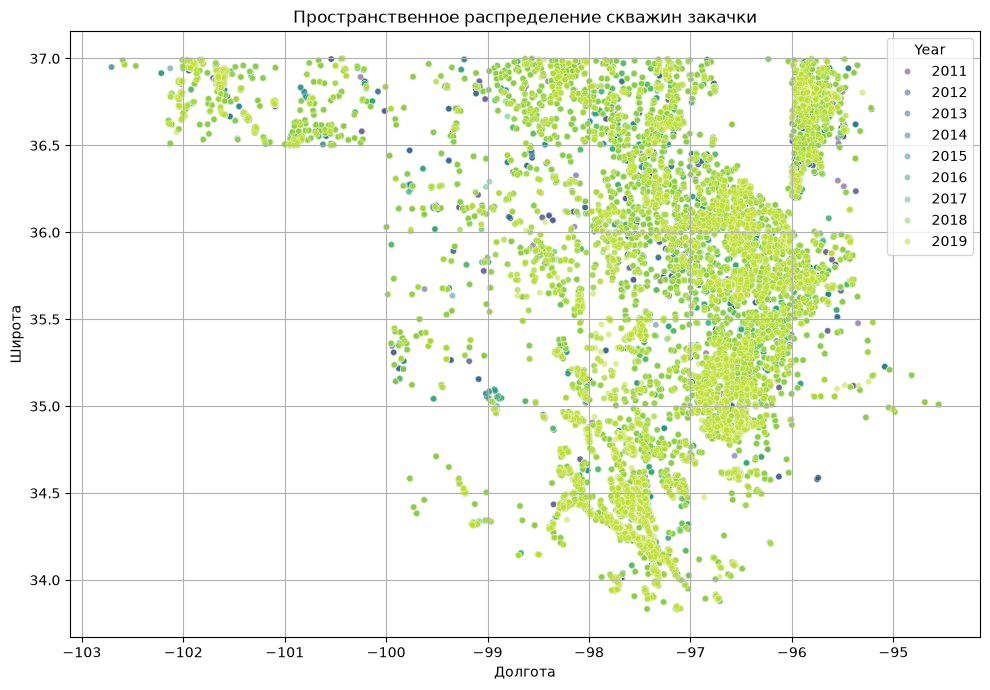

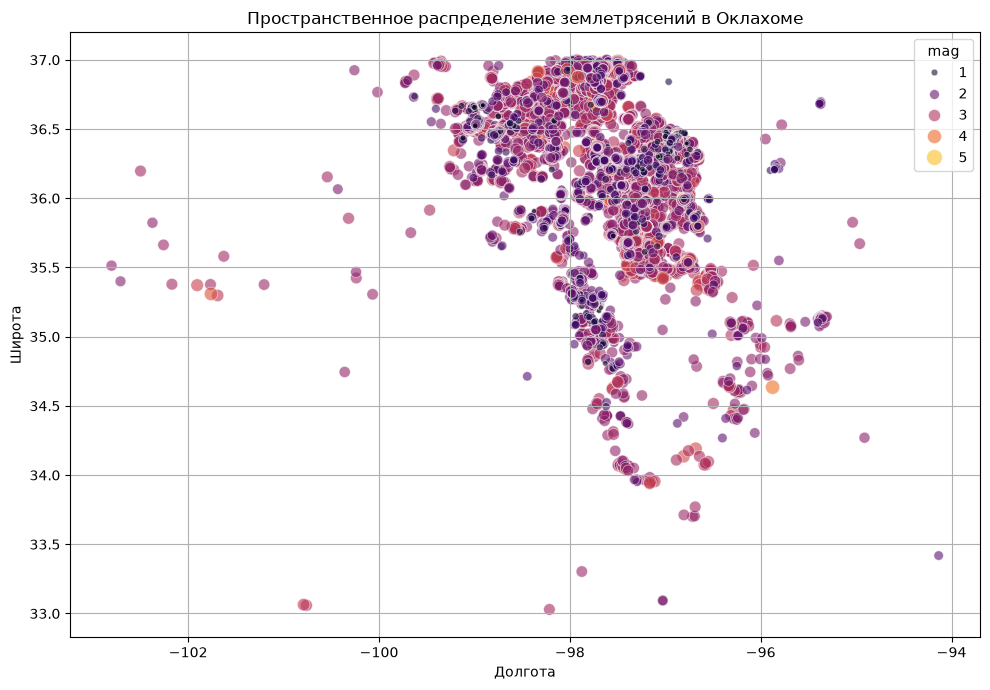

Статистика закачки по округам:
              wells  total_injection  average_latitude  average_longitude
County                                                                   
CARTER         1955     3.342019e+09         34.316759         -97.463549
ALFALFA         142     1.656246e+09         36.820160         -98.311931
CREEK          1085     1.490993e+09         35.923732         -96.368427
STEPHENS       1477     1.450592e+09         34.419895         -97.687240
PONTOTOC        767     1.400413e+09         34.731805         -96.588213
SEMINOLE        566     1.161875e+09         35.135301         -96.613974
WOODS           125     8.359344e+08         36.779540         -98.751646
TEXAS           420     6.073421e+08         36.839536        -101.630358
KAY             260     5.567553e+08         36.782656         -97.186681
POTTAWATOMIE    292     5.081544e+08         35.149611         -96.901093


In [41]:
# 6. Автокорреляция и пространственный анализ


# -------------------------------
# 1. ACF исходных рядов
# -------------------------------

max_lags = min(36, len(injection_series) // 2)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 9)
)

plot_acf(
    injection_series.dropna(),
    lags=max_lags,
    ax=axes[0, 0]
)
axes[0, 0].set_title(
    'ACF исходного ряда закачки'
)

plot_acf(
    log_injection_diff.dropna(),
    lags=max_lags,
    ax=axes[0, 1]
)
axes[0, 1].set_title(
    'ACF стационарного ряда закачки'
)

plot_acf(
    earthquake_series.dropna(),
    lags=max_lags,
    ax=axes[1, 0]
)
axes[1, 0].set_title(
    'ACF исходного ряда землетрясений'
)

plot_acf(
    log_earthquake_diff.dropna(),
    lags=max_lags,
    ax=axes[1, 1]
)
axes[1, 1].set_title(
    'ACF стационарного ряда землетрясений'
)

plt.tight_layout()
plt.show()


# -------------------------------
# 2. Численные значения
# -------------------------------

lags_to_check = [1, 2, 3, 6, 12, 24, 36]

print('Автокорреляция объёма закачки:')

for lag in lags_to_check:
    if lag < len(injection_series):
        print(
            f'Лаг {lag}: '
            f'{injection_series.autocorr(lag=lag):.4f}'
        )


print('\nАвтокорреляция частоты землетрясений:')

for lag in lags_to_check:
    if lag < len(earthquake_series):
        print(
            f'Лаг {lag}: '
            f'{earthquake_series.autocorr(lag=lag):.4f}'
        )


# -------------------------------
# 3. Данные для пространственного анализа
# -------------------------------

spatial_injection = df.dropna(
    subset=['LAT', 'LON', 'Year', 'API']
).copy()

spatial_injection = spatial_injection[
    spatial_injection['LAT'].between(33, 37) &
    spatial_injection['LON'].between(-103, -94) &
    spatial_injection['Year'].between(2011, 2019)
]

spatial_injection['Year'] = (
    spatial_injection['Year'].astype(str)
)


earthquakes_common['Year'] = (
    earthquakes_common['date'].dt.year.astype(str)
)


# -------------------------------
# 4. Скважины закачки
# -------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=spatial_injection,
    x='LON',
    y='LAT',
    hue='Year',
    palette='viridis',
    alpha=0.5,
    s=20
)

plt.title(
    'Пространственное распределение '
    'скважин закачки'
)
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 5. Землетрясения
# -------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=earthquakes_common,
    x='longitude',
    y='latitude',
    hue='mag',
    size='mag',
    palette='inferno',
    sizes=(10, 150),
    alpha=0.6
)

plt.title(
    'Пространственное распределение '
    'землетрясений в Оклахоме'
)
plt.xlabel('Долгота')
plt.ylabel('Широта')
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------------
# 6. Статистика по округам
# -------------------------------

county_statistics = (
    volume_long
    .groupby('County')
    .agg(
        wells=('API', 'nunique'),
        total_injection=(
            'injection_volume',
            'sum'
        ),
        average_latitude=('LAT', 'mean'),
        average_longitude=('LON', 'mean')
    )
    .sort_values(
        'total_injection',
        ascending=False
    )
)

print('Статистика закачки по округам:')
print(county_statistics.head(10))

CCF: закачка и частота землетрясений
    lag       ccf
0   -12 -0.004365
1   -11  0.060803
2   -10  0.173057
3    -9 -0.347709
4    -8  0.300817
5    -7 -0.112625
6    -6  0.172244
7    -5 -0.213025
8    -4  0.040352
9    -3  0.181053
10   -2 -0.111866
11   -1 -0.048419
12    0  0.059501
13    1 -0.051016
14    2  0.181495
15    3 -0.178474
16    4  0.110764
17    5 -0.078448
18    6  0.174345
19    7 -0.162767
20    8  0.013494
21    9  0.096220
22   10 -0.175241
23   11  0.009052
24   12  0.012812

Максимальная связь с частотой: лаг -9; CCF = -0.3477

CCF: закачка и максимальная магнитуда
    lag       ccf
0   -12 -0.124747
1   -11  0.113604
2   -10  0.006109
3    -9 -0.222321
4    -8  0.219324
5    -7 -0.086119
6    -6  0.102986
7    -5 -0.105754
8    -4  0.027025
9    -3  0.033120
10   -2 -0.016935
11   -1  0.017888
12    0 -0.032830
13    1 -0.056447
14    2  0.133520
15    3 -0.011323
16    4  0.042551
17    5 -0.071598
18    6  0.075278
19    7 -0.123800
20    8  0.067763
21    

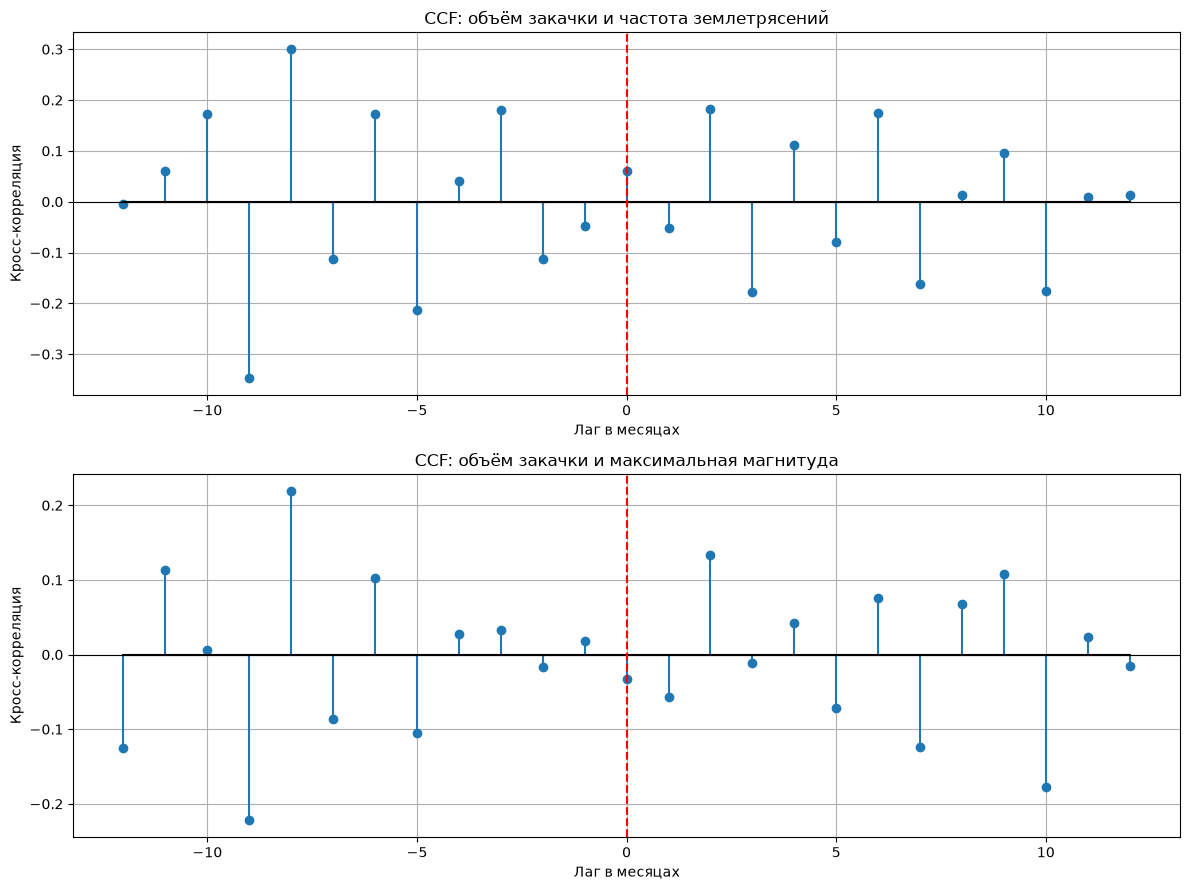

In [42]:
# 7. Кросс-корреляция (CCF)

# -------------------------------
# 1. Месячные показатели землетрясений
# -------------------------------

monthly_earthquake_features = (
    earthquakes_common
    .groupby('date')
    .agg(
        frequency=('mag', 'count'),
        max_magnitude=('mag', 'max')
    )
    .reindex(injection_series.index)
)

monthly_earthquake_features['frequency'] = (
    monthly_earthquake_features['frequency']
    .fillna(0)
)

monthly_earthquake_features['max_magnitude'] = (
    monthly_earthquake_features['max_magnitude']
    .fillna(0)
)


# -------------------------------
# 2. Стационарные ряды
# -------------------------------

ccf_injection = log_injection_diff.copy()

ccf_frequency = (
    np.log1p(
        monthly_earthquake_features['frequency']
    )
    .diff()
    .dropna()
)

ccf_magnitude = (
    np.log1p(
        monthly_earthquake_features['max_magnitude']
    )
    .diff()
    .dropna()
)


# -------------------------------
# 3. Функция расчёта CCF
# -------------------------------

def calculate_ccf(x, y, max_lag=12):
    data = pd.concat(
        [x.rename('x'), y.rename('y')],
        axis=1
    ).dropna()

    x = data['x'].to_numpy()
    y = data['y'].to_numpy()

    max_lag = min(
        max_lag,
        len(data) // 3
    )

    results = []

    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            x_part = x[:lag]
            y_part = y[-lag:]
        elif lag > 0:
            x_part = x[lag:]
            y_part = y[:-lag]
        else:
            x_part = x
            y_part = y

        correlation = np.corrcoef(
            x_part,
            y_part
        )[0, 1]

        results.append({
            'lag': lag,
            'ccf': correlation
        })

    return pd.DataFrame(results)


# -------------------------------
# 4. CCF закачки и частоты
# -------------------------------

ccf_frequency = calculate_ccf(
    ccf_injection,
    ccf_frequency,
    max_lag=12
)

print('CCF: закачка и частота землетрясений')
print(ccf_frequency)

max_frequency_row = ccf_frequency.loc[
    ccf_frequency['ccf'].abs().idxmax()
]

print(
    f'\nМаксимальная связь с частотой: '
    f'лаг {int(max_frequency_row["lag"])}; '
    f'CCF = {max_frequency_row["ccf"]:.4f}'
)


# -------------------------------
# 5. CCF закачки и магнитуды
# -------------------------------

ccf_magnitude_result = calculate_ccf(
    ccf_injection,
    ccf_magnitude,
    max_lag=12
)

print('\nCCF: закачка и максимальная магнитуда')
print(ccf_magnitude_result)

max_magnitude_row = ccf_magnitude_result.loc[
    ccf_magnitude_result['ccf'].abs().idxmax()
]

print(
    f'\nМаксимальная связь с магнитудой: '
    f'лаг {int(max_magnitude_row["lag"])}; '
    f'CCF = {max_magnitude_row["ccf"]:.4f}'
)


# -------------------------------
# 6. Графики CCF
# -------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9)
)

axes[0].stem(
    ccf_frequency['lag'],
    ccf_frequency['ccf'],
    basefmt='k-'
)

axes[0].axhline(
    0,
    color='black',
    linewidth=0.8
)

axes[0].axvline(
    0,
    color='red',
    linestyle='--'
)

axes[0].set_title(
    'CCF: объём закачки и частота землетрясений'
)
axes[0].set_xlabel('Лаг в месяцах')
axes[0].set_ylabel('Кросс-корреляция')
axes[0].grid(True)


axes[1].stem(
    ccf_magnitude_result['lag'],
    ccf_magnitude_result['ccf'],
    basefmt='k-'
)

axes[1].axhline(
    0,
    color='black',
    linewidth=0.8
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--'
)

axes[1].set_title(
    'CCF: объём закачки и максимальная магнитуда'
)
axes[1].set_xlabel('Лаг в месяцах')
axes[1].set_ylabel('Кросс-корреляция')
axes[1].grid(True)

plt.tight_layout()
plt.show()

1.Implementujte a natrénujte prvý pridelený model na riešenie vhodne zvoleného problému, vyhodnoťte jeho výsledky a vysvetlite, ako model pracuje s priestorovými a časovými vlastnosťami dát, aké sú jeho výhody a obmedzenia.

 2. Implementujte a natrénujte druhý pridelený model na riešenie rovnakého problému, porovnajte jeho výsledky s prvým modelom a vysvetlite rozdiely medzi ich architektúrami.


CNN-LSTM - Implementácia, vedieť porovnať architektúru a výsledky s prvými dvoma modelmi

Analyzujte a porovnajte vplyv vtláčania priemyselných odpadových vôd na frekvenciu a intenzitu zemetrasení v priestore a čase v oblasti Oklahomy. Porovnajte presnosť predikcie modelov pri rozličnej intenzite vtláčania na vybraných dátach.
